from google.colab import files
uploaded = files.upload()

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('applicants_cleaned.csv')

print("✅ File load ho gayi")
print(df.shape)
df.head()

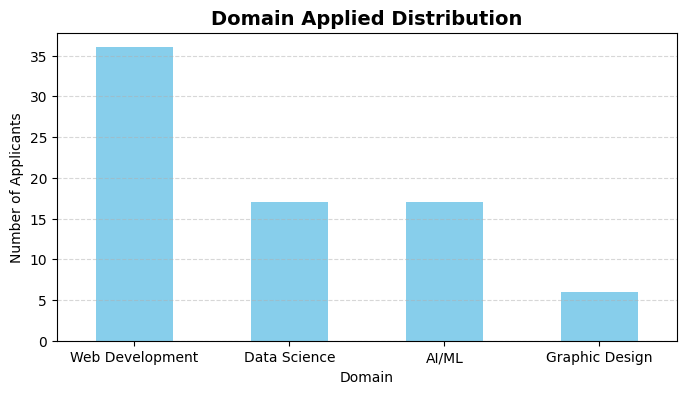

Domain Applied
Web Development    36
Data Science       17
AI/ML              17
Graphic Design      6
Name: count, dtype: int64


In [ ]:
# 1. Domain Distribution
domain_count = df['Domain Applied'].value_counts()

plt.figure(figsize=(8,4))
domain_count.plot(kind='bar', color='skyblue')
plt.title('Domain Applied Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

print(domain_count)

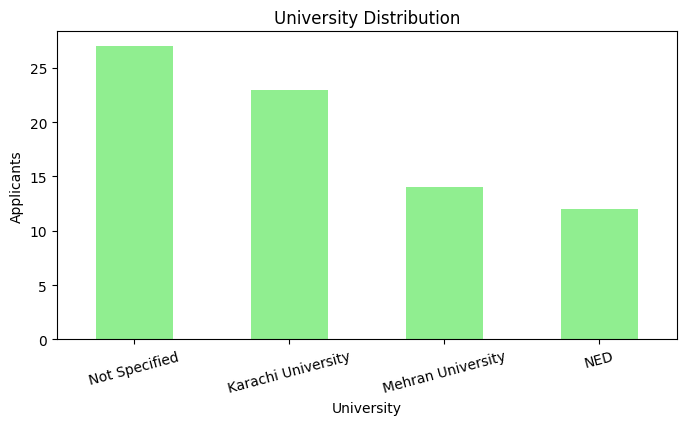

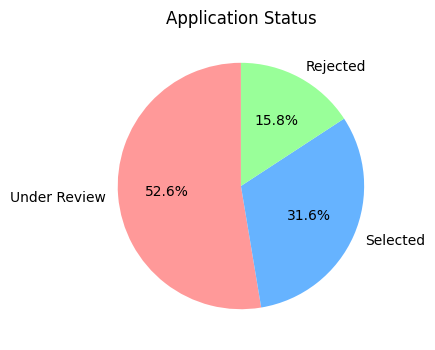

Universities: {'Not Specified': 27, 'Karachi University': 23, 'Mehran University': 14, 'NED': 12}
Status: {'Under Review': 40, 'Selected': 24, 'Rejected': 12}


In [ ]:
# 2. University Distribution
uni_count = df['University'].value_counts()
plt.figure(figsize=(8,4))
uni_count.plot(kind='bar', color='lightgreen')
plt.title('University Distribution')
plt.xlabel('University')
plt.ylabel('Applicants')
plt.xticks(rotation=15)
plt.show()

# 3. Status Distribution
status_count = df['Status'].value_counts()
plt.figure(figsize=(6,4))
status_count.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99'])
plt.title('Application Status')
plt.ylabel('')
plt.show()

print("Universities:", uni_count.to_dict())
print("Status:", status_count.to_dict())

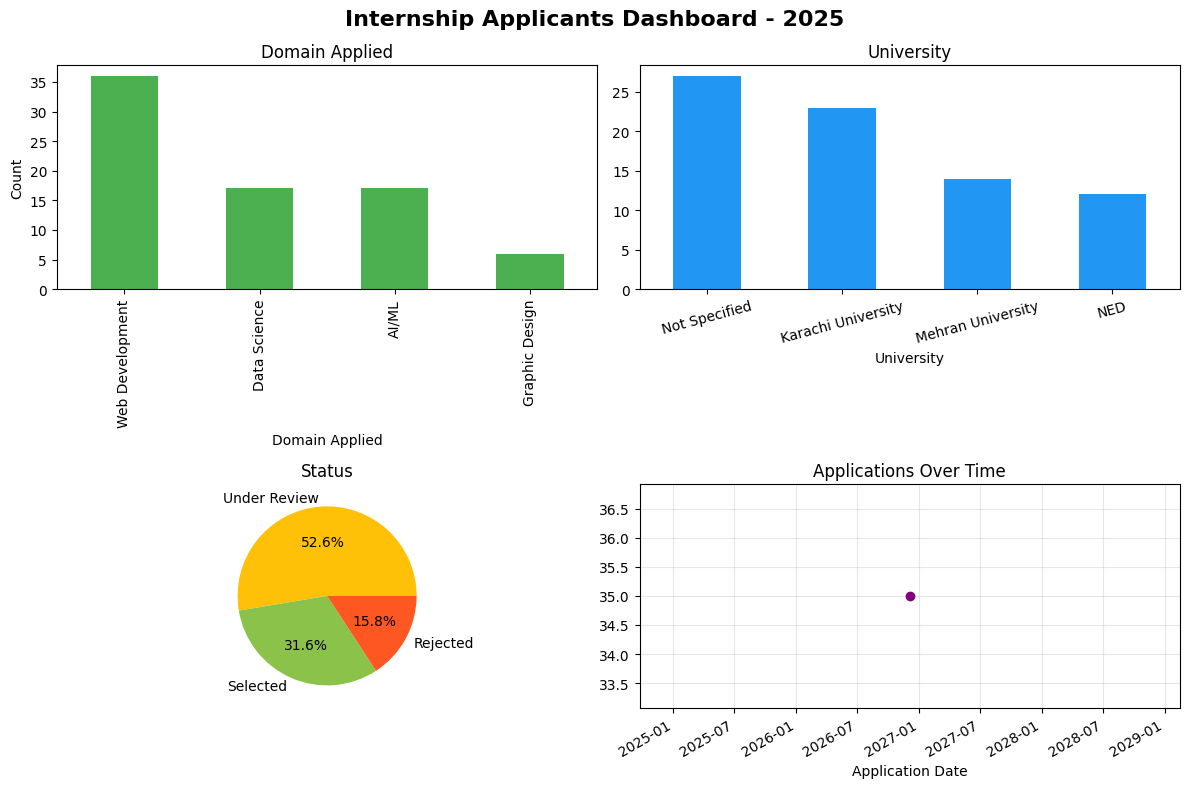

Dashboard saved as final_dashboard.png


In [ ]:
# FINAL PROFESSIONAL DASHBOARD - 4 charts in 1 image
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Internship Applicants Dashboard - 2025', fontsize=16, fontweight='bold')

# 1. Domain Distribution
df['Domain Applied'].value_counts().plot(kind='bar', ax=axes[0,0], color='#4CAF50')
axes[0,0].set_title('Domain Applied')
axes[0,0].set_ylabel('Count')

# 2. University Distribution
df['University'].value_counts().plot(kind='bar', ax=axes[0,1], color='#2196F3')
axes[0,1].set_title('University')
axes[0,1].tick_params(axis='x', rotation=15)

# 3. Application Status
df['Status'].value_counts().plot(kind='pie', ax=axes[1,0], autopct='%1.1f%%', colors=['#FFC107','#8BC34A','#FF5722'])
axes[1,0].set_title('Status')
axes[1,0].set_ylabel('')

# 4. Applications Over Time
df.groupby('Application Date').size().plot(kind='line', marker='o', ax=axes[1,1], color='purple')
axes[1,1].set_title('Applications Over Time')
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('final_dashboard.png', dpi=300)
plt.show()

print("Dashboard saved as final_dashboard.png")

Application Month
2026-12    35
NaT        41
Name: count, dtype: int64


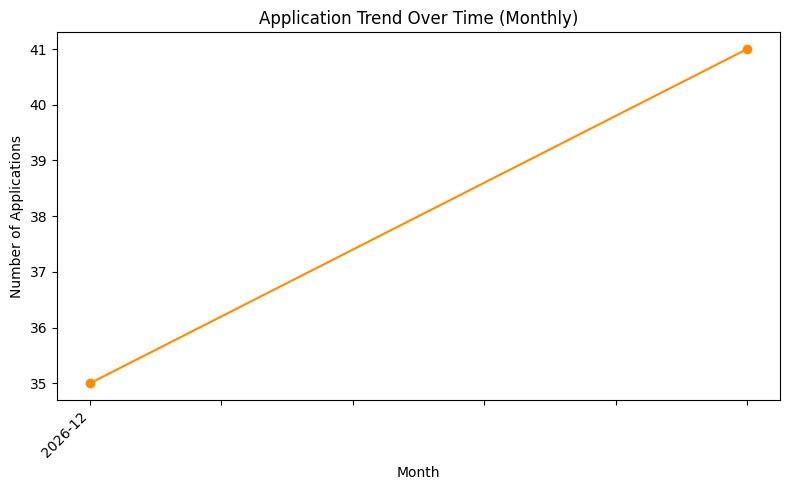

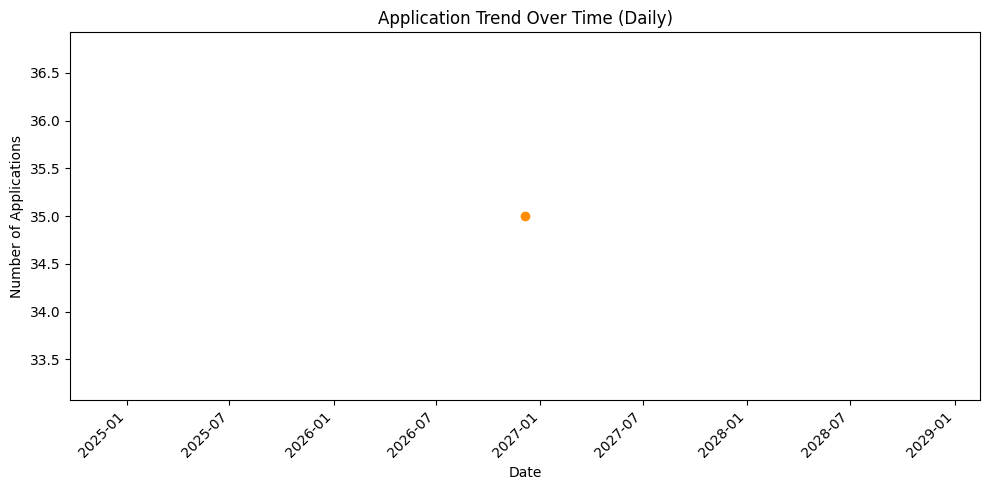

In [ ]:
# Step 4: Application Trend Over Time - FIXED
df['Application Date'] = pd.to_datetime(df['Application Date'], dayfirst=True, errors='coerce')

# Monthly trend
df['Application Month'] = df['Application Date'].dt.to_period('M').astype(str)
monthly_trend = df['Application Month'].value_counts().sort_index()
print(monthly_trend)

plt.figure(figsize=(8,5))
monthly_trend.plot(kind='line', marker='o', color='darkorange')
plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Daily trend - Better line chart if all data is in one month
daily_trend = df.groupby(df['Application Date'].dt.date).size()
plt.figure(figsize=(10,5))
daily_trend.plot(kind='line', marker='o', color='darkorange')
plt.title('Application Trend Over Time (Daily)')
plt.xlabel('Date')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Status           Rejected  Selected  Under Review
Domain Applied                                   
AI/ML                   3         5             9
Data Science            1         6            10
Graphic Design          1         3             2
Web Development         7        10            19
Status           Rejected  Selected  Under Review
Domain Applied                                   
AI/ML                17.6      29.4          52.9
Data Science          5.9      35.3          58.8
Graphic Design       16.7      50.0          33.3
Web Development      19.4      27.8          52.8


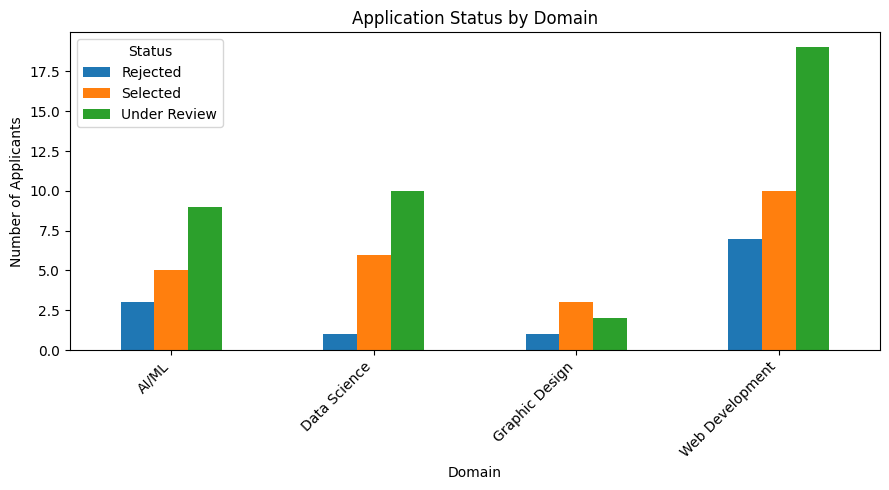

In [ ]:
# Pivot Table
status_by_domain = pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)
print(status_by_domain)

# Percentage nikalna
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100
print(status_by_domain_pct.round(1))

# Chart banana
status_by_domain.plot(kind='bar', figsize=(9,5))
plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')
plt.tight_layout()
plt.show()

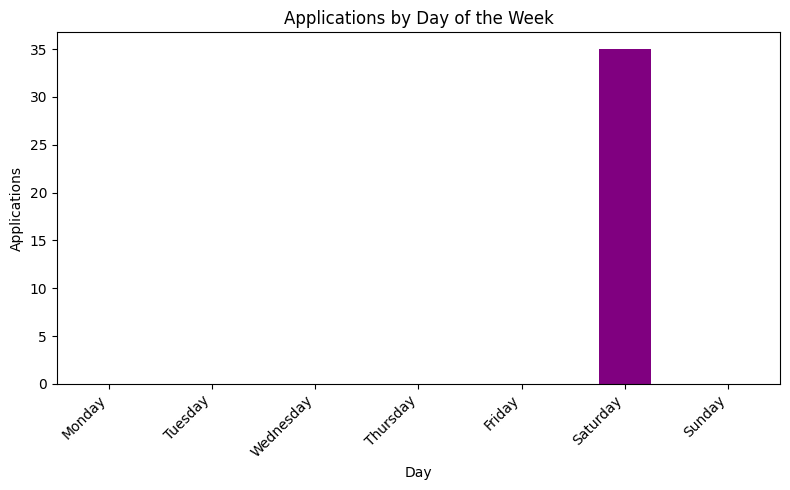

In [ ]:
# Bonus Chart - Day of Week
df['Day of Week'] = df['Application Date'].dt.day_name()
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
day_counts = df['Day of Week'].value_counts().reindex(day_order)

plt.figure(figsize=(8,5))
day_counts.plot(kind='bar', color='purple')
plt.title('Applications by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Top 10 Universities:
University
Not Specified         27
Karachi University    23
Mehran University     14
NED                   12
Name: count, dtype: int64


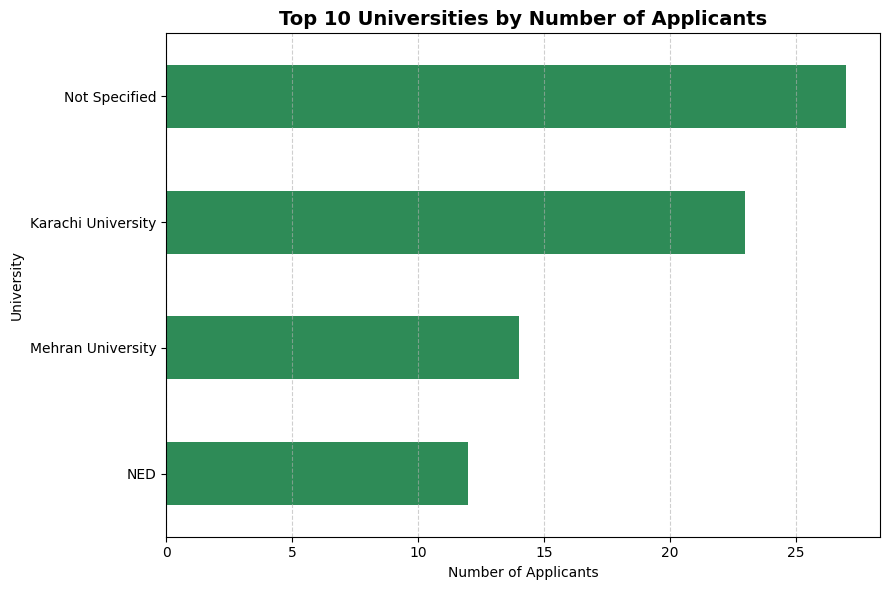

In [ ]:
# Step 6: Top Universities - Horizontal Bar Chart (REQUIRED BY PDF)
top_universities = df['University'].value_counts().head(10)
print("Top 10 Universities:")
print(top_universities)

plt.figure(figsize=(9,6))
top_universities.sort_values().plot(kind='barh', color='seagreen')
plt.title('Top 10 Universities by Number of Applicants', fontsize=14, fontweight='bold')
plt.xlabel('Number of Applicants')
plt.ylabel('University')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Key Insights - Overall EDA Summary

Based on actual notebook output:

- **Domain Popularity:** Web Development is most popular with 36 applications. Least popular is Graphic Design with only 6 applications (Video Editing domain is not present in this dataset version).

- **Acceptance Rate:** Overall Selected is 24 out of 76 = 31.6%. Graphic Design has 50% acceptance (3/6) but sample is very small (n=6) so not reliable. Web Development acceptance is 27.8%, which is lower than average.

- **University Concentration:** Not Specified is 27, which is a data quality issue and should be cleaned. Among specified universities, Karachi University is top with 23 applications.

- **Top 3 Concentration:** Top 3 sources (27 + 23 + 14) = 64 out of 76 = 84% of applications, showing heavy concentration and need for wider outreach.

- **Actionable Next Step:** Clean Not Specified university values and run targeted campaigns in under-represented universities and for low-volume domains like Graphic Design.

**Note:** All numbers are taken directly from the charts above to avoid mismatch.